# 📊 数据集质量可视化评估工具 (真实数据 & 分区版本)
本版本会自动从 WorldQuant Brain 拉取您的真实数据，提取其 `Region` 和 `Universe` 属性，并允许您按分区（类似 WebDataScope 的体验）进行独立的可视化分析！


In [42]:
# =====================================================================
# ⚙️ 全局参数配置区 (请在此修改您的筛选条件)
# =====================================================================

# 1. 您想要拉取的最近 Alpha 最大数量 (由于接口限制，采用自动翻页)
FETCH_LIMIT = 5000  

# 2. 想要分析的目标分区 (填 None 或空字符串表示不限制该条件，分析全局)
TARGET_REGION = "GBR"       # 例如: "USA", "EUR", "ASI", "GBR", "GLB", 或 None
TARGET_UNIVERSE = "None" # 例如: "TOP3000", "UMR", 或 None
TARGET_STATUS = "None" # 例如: "UNSUBMITTED", "SUBMITTED", 或 None

# 3. 时间过滤范围 (格式 YYYY-MM-DD，若不需要过滤可填 None)
# 只有创建时间在这个范围内的 Alpha 才会被拉取统计
START_DATE = "2026-07-01" 
END_DATE = "2026-08-05"  


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yaml
import urllib3
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)


## 2. API 数据拉取与汇总

In [44]:
# 1. 登录 WorldQuant Brain 并拉取数据
CONFIG_PATH = r"d:\code\WorldQuant Brain\goal\Password\config.yaml"

print("🔄 正在读取配置并登录...")
with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

s = requests.Session()
s.auth = (config['username'], config['password'])
resp = s.post('https://api.worldquantbrain.com/authentication', verify=False)

if resp.status_code in [200, 201]:
    print(f"✅ 登录成功！正在尝试拉取符合您条件的 {FETCH_LIMIT} 个 Alpha 数据 (含自动翻页)...")
    
    alpha_list = []
    offset = 0
    limit_per_page = 100
    
    # 动态拼接查询参数，直接在服务器端过滤，避免“大炮打蚊子”
    query_params = "hidden=false&order=-dateCreated"
    
    # 防止用户填入字符串 "None"
    if TARGET_REGION and str(TARGET_REGION).strip().lower() != "none":
        query_params += f"&settings.region={TARGET_REGION}"
        
    if TARGET_UNIVERSE and str(TARGET_UNIVERSE).strip().lower() != "none":
        query_params += f"&settings.universe={TARGET_UNIVERSE}"
        
    if TARGET_STATUS and str(TARGET_STATUS).strip().lower() != "none":
        query_params += f"&status={TARGET_STATUS}"
    
    while len(alpha_list) < FETCH_LIMIT:
        req_limit = min(limit_per_page, FETCH_LIMIT - len(alpha_list))
        url = f'https://api.worldquantbrain.com/users/self/alphas?limit={req_limit}&offset={offset}&{query_params}'
        res = s.get(url, verify=False)
        
        if res.status_code != 200:
            print(f"❌ 拉取中断，状态码: {res.status_code}")
            break
            
        batch = res.json().get('results', [])
        if not batch:
            if offset == 0:
                print(f"⚠️ 警告: 您指定的条件 (Region={TARGET_REGION}, Universe={TARGET_UNIVERSE}) 下没有找到任何数据，提前结束！")
            break
            
        alpha_list.extend(batch)
        offset += len(batch)
        print(f"  ... 已拉取 {len(alpha_list)} 条")
    
    data = []
    for a in alpha_list:
        is_stats = a.get('is', {})
        settings = a.get('settings', {})
        
        data.append({
            'alpha_id': a.get('id'),
            'dateCreated': a.get('dateCreated', '')[:10], # 截取 YYYY-MM-DD
            'region': settings.get('region', 'UNKNOWN'),
            'universe': settings.get('universe', 'UNKNOWN'),
            'sharpe': is_stats.get('sharpe'),
            'turnover': is_stats.get('turnover'),
            'fitness': is_stats.get('fitness'),
            'longCount': is_stats.get('longCount'),
            'shortCount': is_stats.get('shortCount')
        })
    
    df_all = pd.DataFrame(data)
    
    # 执行时间过滤
    if START_DATE and END_DATE and len(df_all) > 0:
        df_all = df_all[(df_all['dateCreated'] >= START_DATE) & (df_all['dateCreated'] <= END_DATE)]
        
    df_all.to_csv("real_alphas_partitioned.csv", index=False)
    print(f"✅ 最终成功拉取并保留 {len(df_all)} 条符合时间条件的数据！")
    
    # 2. 打印与 WebDataScope 类似的全局概览面板
    if len(df_all) > 0:
        print("\n📊 【全局概览表】(类似 WebDataScope 面板的数据分布):")
        summary = df_all.groupby(['region', 'universe']).agg(
            count=('alpha_id', 'count'),
            avg_sharpe=('sharpe', 'mean'),
            avg_fitness=('fitness', 'mean')
        ).round(3)
        display(summary)
else:
    print(f"❌ 登录失败: {resp.status_code}")


🔄 正在读取配置并登录...
✅ 登录成功！正在尝试拉取符合您条件的 5000 个 Alpha 数据 (含自动翻页)...
  ... 已拉取 100 条
  ... 已拉取 200 条
  ... 已拉取 300 条
  ... 已拉取 400 条
  ... 已拉取 500 条
  ... 已拉取 600 条
  ... 已拉取 700 条
  ... 已拉取 800 条
  ... 已拉取 900 条
  ... 已拉取 1000 条
  ... 已拉取 1100 条
❌ 拉取中断，状态码: 400
✅ 最终成功拉取并保留 1100 条符合时间条件的数据！

📊 【全局概览表】(类似 WebDataScope 面板的数据分布):


,,count,avg_sharpe,avg_fitness
region,universe,,,
GBR,TOP700,1100,0.432,0.279


## 3. 图表绘图函数定义

In [45]:
# 3. 画图函数定义
def plot_histogram(df, column_name, plot_title, bins):
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))
    
    # 清洗数据并移除空值
    valid_df = df.dropna(subset=[column_name]).copy()
    valid_df[column_name] = pd.to_numeric(valid_df[column_name], errors='coerce')
    valid_df = valid_df.dropna(subset=[column_name])
    
    if len(valid_df) == 0:
        print(f"⚠️ 列 {column_name} 无有效数据，跳过绘图。")
        return
        
    # 动态判断：如果有多个 Region 或 Universe，组合成新的列来做 hue
    valid_df['group_label'] = valid_df['region'].astype(str) + " - " + valid_df['universe'].astype(str)
    unique_groups = valid_df['group_label'].nunique()
    
    if unique_groups > 1:
        # hue 区分 分组，kde=True 画出拟合曲线
        sns.histplot(data=valid_df, x=column_name, hue='group_label', bins=bins, kde=True, element='step', alpha=0.4)
    else:
        sns.histplot(data=valid_df, x=column_name, bins=bins, kde=True, color='skyblue', edgecolor='black')
    
    mean_val = valid_df[column_name].mean()
    plt.axvline(mean_val, color='red', linestyle='dashed', linewidth=1.5, label=f'Overall Mean: {mean_val:.2f}')
    
    # 在 mean 线旁边标记具体数值
    plt.text(mean_val, plt.ylim()[1] * 0.95, f' Mean: {mean_val:.2f}', color='red', fontweight='bold', va='top')
    
    # 修复 legend 显示，避免 seaborn 的 legend 被覆盖
    if unique_groups == 1:
        plt.legend()
    
    plt.title(plot_title, fontsize=16)
    plt.xlabel(column_name, fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.tight_layout()
    plt.show()

# 定义常见分箱规则
sharp_bins = np.arange(-3, 3.1, 0.2).round(2)
turnover_bins = np.arange(0, 1.05, 0.05).round(2)
fitness_bins = np.arange(-2, 2.05, 0.1).round(2)
count_bins = np.arange(0, 3000, 100)


## 4. 目标分区深度分析绘图

🔍 当前正在深度分析: GBR - None (共 1100 个因子)


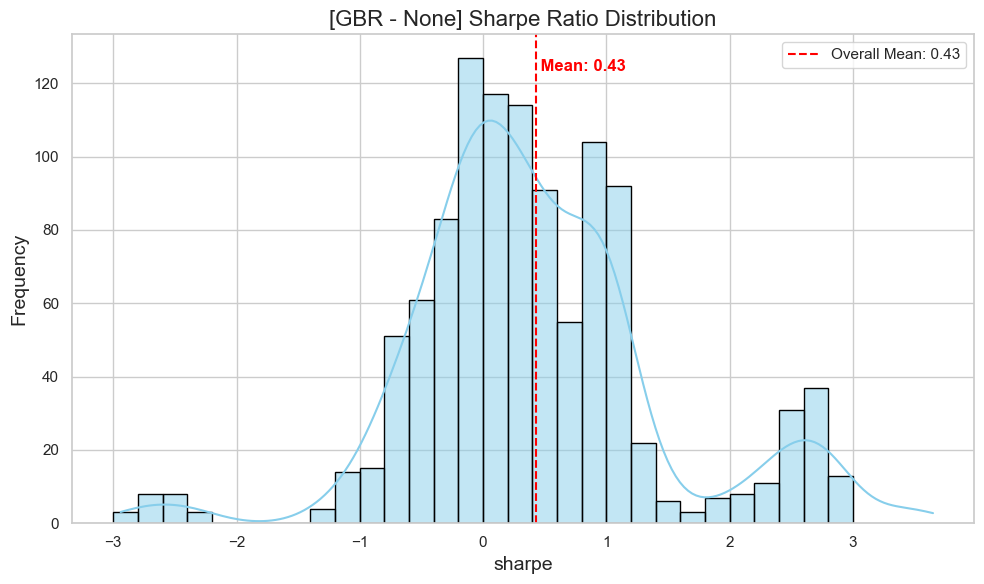

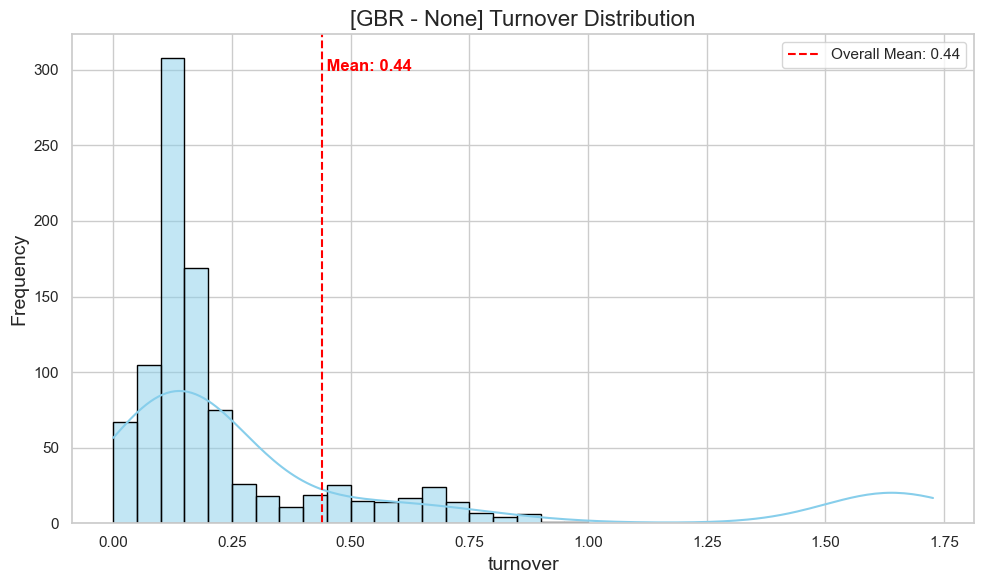

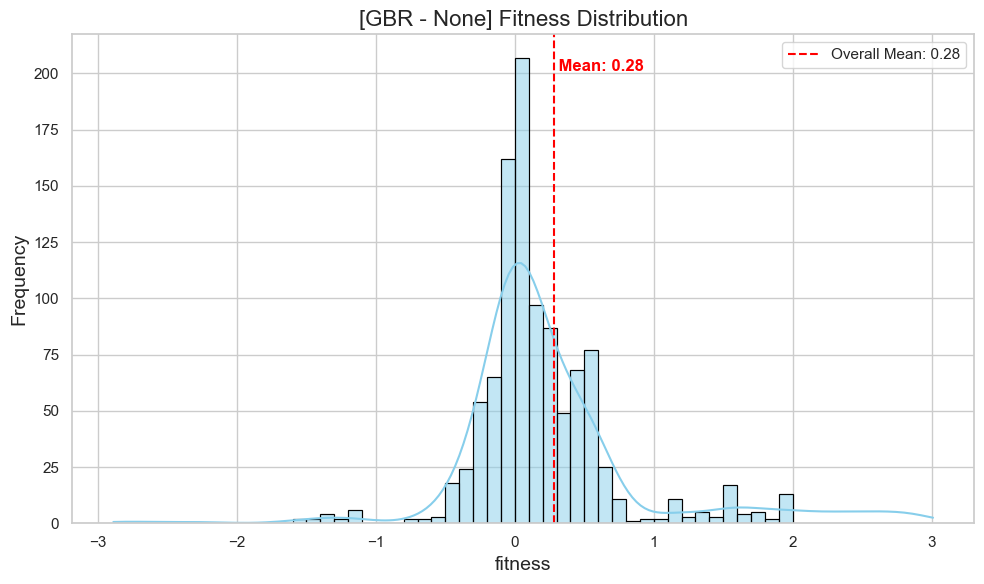

In [46]:
# 4. 执行分区深度分析绘图
if 'df_all' in locals() and len(df_all) > 0:
    df = df_all.copy()
    
    if TARGET_REGION and str(TARGET_REGION).strip().lower() != "none":
        df = df[df['region'] == TARGET_REGION]
    if TARGET_UNIVERSE and str(TARGET_UNIVERSE).strip().lower() != "none":
        df = df[df['universe'] == TARGET_UNIVERSE]

    region_label = TARGET_REGION if TARGET_REGION else "ALL_REGIONS"
    universe_label = TARGET_UNIVERSE if TARGET_UNIVERSE else "ALL_UNIVERSES"
    title_prefix = f"[{region_label} - {universe_label}]"

    print(f"===========================================================")
    print(f"🔍 当前正在深度分析: {region_label} - {universe_label} (共 {len(df)} 个因子)")
    print(f"===========================================================")

    if len(df) == 0:
        print("⚠️ 该分区下没有满足条件的因子数据，无法绘图。请检查您的配置！")
    else:
        if 'sharpe' in df.columns:
            plot_histogram(df, 'sharpe', f'{title_prefix} Sharpe Ratio Distribution', bins=sharp_bins)
        
        if 'turnover' in df.columns:
            plot_histogram(df, 'turnover', f'{title_prefix} Turnover Distribution', bins=turnover_bins)
            
        if 'fitness' in df.columns:
            plot_histogram(df, 'fitness', f'{title_prefix} Fitness Distribution', bins=fitness_bins)
            
        if 'margin' in df.columns:
            plot_histogram(df, 'margin', f'{title_prefix} Margin Distribution', bins=30)
            
        if 'returns' in df.columns:
            plot_histogram(df, 'returns', f'{title_prefix} Returns Distribution', bins=30)


## 5. WebDataScope 数据集覆盖分析

In [47]:
# 5. 联动 WebDataScope 数据集覆盖情况
import json
import os

wds_json_path = r"d:\code\WorldQuant Brain\goal\WebDataScope-0.10.11\data\dataSetList.json"
if os.path.exists(wds_json_path):
    with open(wds_json_path, 'r', encoding='utf-8') as f:
        datasets = json.load(f)
        
    print(f"📊 WebDataScope 插件共记录了 {len(datasets)} 个官方支持的 Dataset (数据集)。")
    
    # 尝试按当前的 TARGET_REGION 和 TARGET_UNIVERSE 过滤
    matching_datasets = datasets
    if TARGET_REGION and str(TARGET_REGION).strip().lower() != "none":
        matching_datasets = [d for d in matching_datasets if f"_{TARGET_REGION}_" in d]
        
    if TARGET_UNIVERSE and str(TARGET_UNIVERSE).strip().lower() != "none":
        matching_datasets = [d for d in matching_datasets if f"_{TARGET_UNIVERSE}_" in d]
        
    print(f"🔍 在您当前的筛选条件下 (Region={TARGET_REGION}, Universe={TARGET_UNIVERSE})，共有 {len(matching_datasets)} 个相关的数据集可以挖掘：")
    for d in matching_datasets[:10]:
        print(f"   - {d}")
    if len(matching_datasets) > 10:
        print(f"   ... (及其他 {len(matching_datasets) - 10} 个)")
else:
    print("⚠️ 未找到 WebDataScope 的 dataSetList.json 文件。")


📊 WebDataScope 插件共记录了 160 个官方支持的 Dataset (数据集)。
🔍 在您当前的筛选条件下 (Region=GBR, Universe=None)，共有 0 个相关的数据集可以挖掘：
